In [125]:
import pandas as pd
import matplotlib.pyplot as plt
import sklearn.cluster as cluster
from PIL.Image import init
from matplotlib.pyplot import gray, subplot, subplots, figure
from scipy.ndimage import label
from scipy.stats import shapiro
import seaborn as sns
from scipy.stats.mstats import winsorize
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder


In [32]:
data = pd.read_csv('spotify.csv')
cl_data = data[data['speechiness']<=60].copy()

In [33]:
cl_data.describe()
cl_data.info()

<class 'pandas.DataFrame'>
Index: 952 entries, 0 to 952
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   track_name            952 non-null    str    
 1   released_year         952 non-null    int64  
 2   in_spotify_playlists  952 non-null    int64  
 3   in_spotify_charts     951 non-null    str    
 4   streams               952 non-null    int64  
 5   in_apple_playlists    952 non-null    int64  
 6   in_apple_charts       950 non-null    float64
 7   bpm                   952 non-null    int64  
 8   mode                  952 non-null    str    
 9   energy                952 non-null    int64  
 10  instrumentalness      952 non-null    int64  
 11  liveness              952 non-null    int64  
 12  speechiness           952 non-null    int64  
dtypes: float64(1), int64(9), str(3)
memory usage: 104.1 KB


In [34]:
cl_data.drop(columns='track_name',inplace=True)

In [35]:
cl_data['mode'].unique()

<StringArray>
['Major', 'Minor']
Length: 2, dtype: str

In [36]:
cl_data['mode']=cl_data['mode'].map({'Major':1,'Minor':0})

In [37]:
cl_data.drop(columns='instrumentalness',inplace=True)

In [38]:
cl_data.info()

<class 'pandas.DataFrame'>
Index: 952 entries, 0 to 952
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   released_year         952 non-null    int64  
 1   in_spotify_playlists  952 non-null    int64  
 2   in_spotify_charts     951 non-null    str    
 3   streams               952 non-null    int64  
 4   in_apple_playlists    952 non-null    int64  
 5   in_apple_charts       950 non-null    float64
 6   bpm                   952 non-null    int64  
 7   mode                  952 non-null    int64  
 8   energy                952 non-null    int64  
 9   liveness              952 non-null    int64  
 10  speechiness           952 non-null    int64  
dtypes: float64(1), int64(9), str(1)
memory usage: 89.2 KB


In [39]:
cl_data['in_spotify_charts'] = pd.to_numeric(cl_data['in_spotify_charts'],errors='coerce')

In [24]:
cl_data.isna().sum()

released_year           0
in_spotify_playlists    0
in_spotify_charts       2
streams                 0
in_apple_playlists      0
in_apple_charts         2
bpm                     0
mode                    0
energy                  0
liveness                0
speechiness             0
dtype: int64

In [40]:
cl_data.loc[cl_data['in_spotify_charts'].isnull(), 'in_spotify_charts'] = cl_data['in_spotify_charts'].median()
cl_data.loc[cl_data['in_apple_charts'].isnull(), 'in_apple_charts'] = cl_data['in_apple_charts'].median()

In [41]:
cl_data.describe()

,released_year,in_spotify_playlists,in_spotify_charts,streams,in_apple_playlists,in_apple_charts,bpm,mode,energy,liveness,speechiness
count,952.000000,952.000000,952.000000,9.520000e+02,952.000000,952.000000,952.000000,952.000000,952.000000,952.000000,952.000000
mean,2018.233193,5205.304622,11.861345,5.146578e+08,67.876050,51.717437,122.555672,0.577731,64.297269,18.211134,10.074580
std,11.120988,7900.140377,19.329227,5.666776e+08,86.464421,50.377346,28.068585,0.494181,16.549733,13.718308,9.762894
min,1930.000000,31.000000,0.000000,2.762000e+03,0.000000,0.000000,65.000000,0.000000,9.000000,3.000000,2.000000
25%,2020.000000,878.750000,0.000000,1.420017e+08,13.000000,7.000000,99.750000,0.000000,53.000000,10.000000,4.000000
50%,2022.000000,2225.000000,3.000000,2.912715e+08,34.000000,38.000000,121.000000,1.000000,66.000000,12.000000,6.000000
75%,2022.000000,5573.750000,16.000000,6.738690e+08,88.000000,86.000000,140.250000,1.000000,77.000000,24.000000,11.000000
max,2023.000000,52898.000000,147.000000,3.703895e+09,672.000000,275.000000,206.000000,1.000000,97.000000,97.000000,59.000000


In [44]:
cl_data.loc[cl_data['in_spotify_charts']==0,'in_spotify_charts'] = cl_data['in_spotify_charts'].max()
cl_data.loc[cl_data['in_apple_charts']==0,'in_apple_charts'] = cl_data['in_apple_charts'].max()

In [45]:
cl_data.describe()

,released_year,in_spotify_playlists,in_spotify_charts,streams,in_apple_playlists,in_apple_charts,bpm,mode,energy,liveness,speechiness
count,952.000000,952.000000,952.000000,9.520000e+02,952.000000,952.000000,952.000000,952.000000,952.000000,952.000000,952.000000
mean,1164.396008,3258.832983,83.162815,3.282358e+08,114.491597,111.390756,139.019958,72.092437,107.504202,81.502101,76.722689
std,929.329883,7026.192859,72.911480,5.445523e+08,82.505227,60.093553,34.507053,80.899867,51.642181,73.344369,77.078891
min,147.000000,31.000000,1.000000,1.470000e+02,1.000000,1.000000,67.000000,0.000000,9.000000,3.000000,2.000000
25%,147.000000,147.000000,12.000000,1.470000e+02,37.000000,68.750000,120.000000,1.000000,66.000000,12.000000,5.000000
50%,2012.000000,289.000000,52.000000,6.619927e+07,147.000000,144.500000,147.000000,1.000000,87.000000,38.000000,26.500000
75%,2022.000000,2877.250000,147.000000,4.035644e+08,147.000000,147.000000,147.000000,147.000000,147.000000,147.000000,147.000000
max,2023.000000,51979.000000,275.000000,3.703895e+09,672.000000,275.000000,275.000000,275.000000,275.000000,275.000000,275.000000


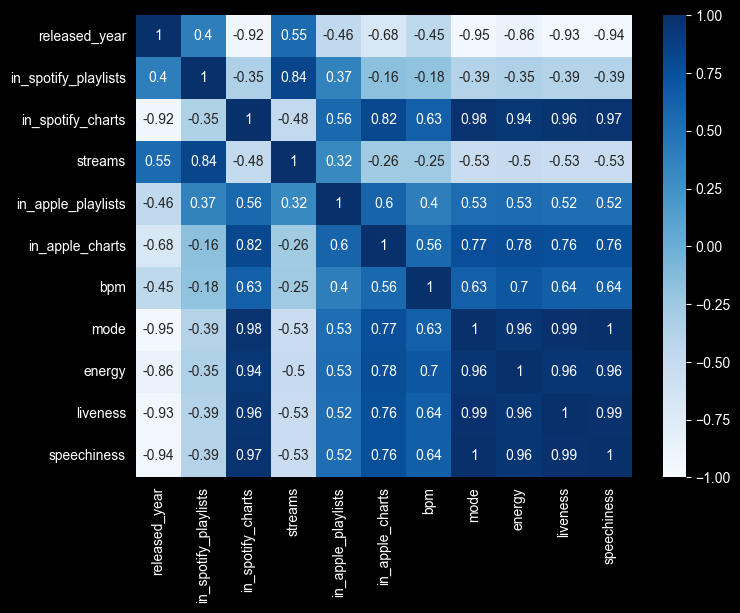

In [49]:
plt.figure(figsize=(8,6))
sns.heatmap(cl_data.corr(),cmap=plt.cm.Blues,vmin=-1,vmax=1,annot=True)
plt.show()

In [50]:
cl_data.drop(columns=['speechiness','liveness'],inplace=True)

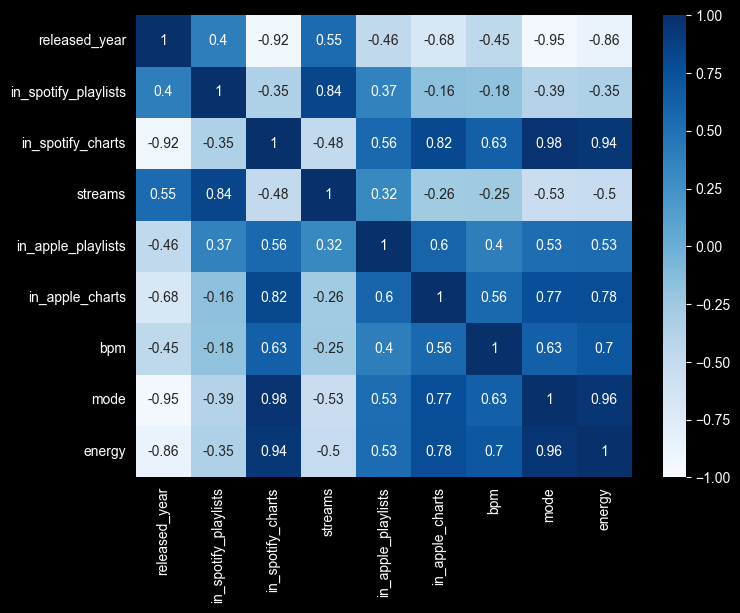

In [53]:
plt.figure(figsize=(8,6))
sns.heatmap(cl_data.corr(),cmap=plt.cm.Blues,vmin=-1,vmax=1,annot=True)
plt.show()

In [ ]:
plt.figure(figsize=(8,6))
sns.heatmap(cl_data.corr(),cmap=plt.cm.Blues,vmin=-1,vmax=1,annot=True)
plt.show()

In [54]:
cl_data.drop(columns=['streams','in_apple_charts'],inplace=True)

In [58]:
def draw_box(podaci,naziv):
    plt.boxplot(podaci)
    plt.xlabel(naziv)
    plt.show()

In [ ]:
def boxx_draw(podaci,naziv):
    plt.boxplot(podaci)
    plt.xlabel(naziv)
    plt.show()

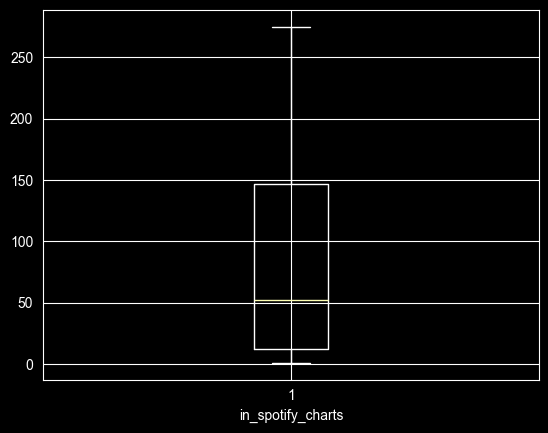

In [59]:
draw_box(cl_data['in_spotify_charts'],'in_spotify_charts')

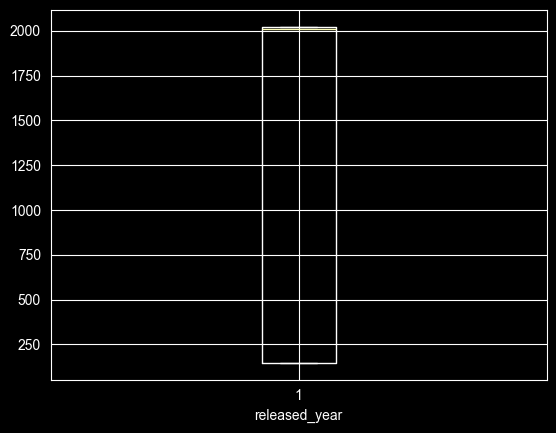

In [60]:
draw_box(cl_data['released_year'],'released_year')

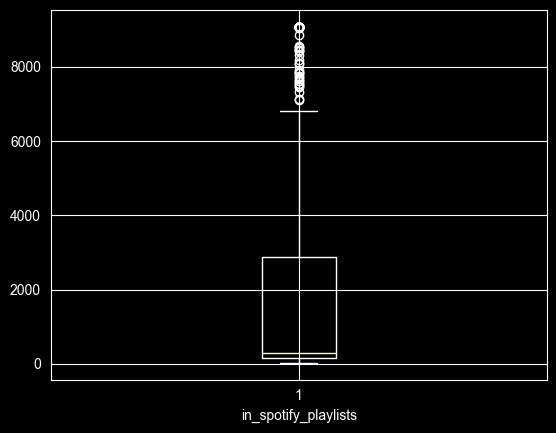

In [65]:
draw_box(cl_data['in_spotify_playlists'],'in_spotify_playlists')

winsorize_res = winsorize(cl_data['in_spotify_playlists'],limits=(0.00,0.10))
draw_box(winsorize_res,'in_spotify_playlists')

cl_data.drop(columns=['in_spotify_playlists'],inplace=True)

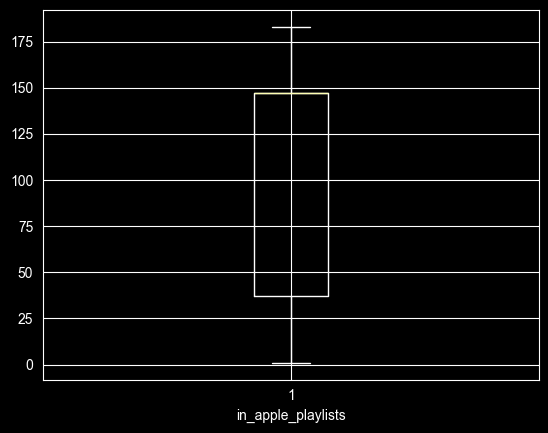

In [68]:
draw_box(cl_data['in_apple_playlists'],'in_apple_playlists')

winsorize_res = winsorize(cl_data['in_apple_playlists'],limits=(0.00,0.10))
draw_box(winsorize_res,'in_apple_playlists')
cl_data['in_apple_playlists']=winsorize_res

In [69]:
cl_data.info()

<class 'pandas.DataFrame'>
Index: 952 entries, 0 to 952
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   released_year       952 non-null    int64  
 1   in_spotify_charts   952 non-null    float64
 2   in_apple_playlists  952 non-null    int64  
 3   bpm                 952 non-null    int64  
 4   mode                952 non-null    int64  
 5   energy              952 non-null    int64  
dtypes: float64(1), int64(5)
memory usage: 84.4 KB


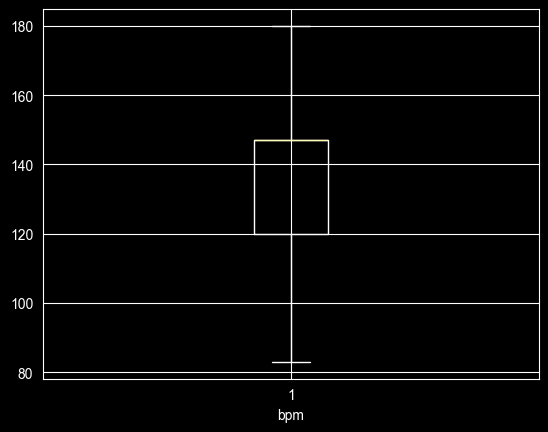

In [90]:
draw_box(cl_data['bpm'],'bpm')

winsorize_res = winsorize(cl_data['bpm'],limits=(0.02,0.05))
draw_box(winsorize_res,'bpm')
cl_data['bpm']=winsorize_res

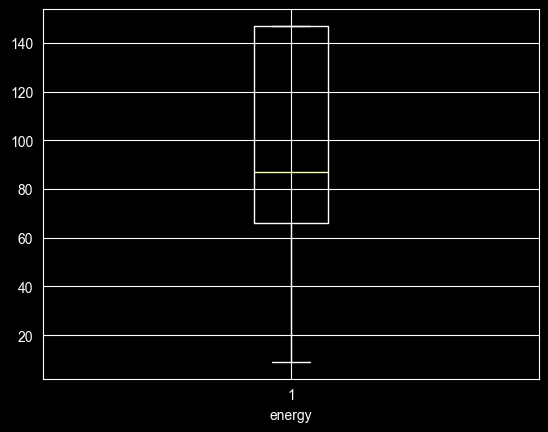

In [95]:
draw_box(cl_data['energy'],'energy')
winsorize_res = winsorize(cl_data['energy'],limits=(0.00,0.05))
draw_box(winsorize_res,'energy')
cl_data['energy']=winsorize_res

In [96]:
cl_data.info()

<class 'pandas.DataFrame'>
Index: 952 entries, 0 to 952
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   released_year       952 non-null    int64  
 1   in_spotify_charts   952 non-null    float64
 2   in_apple_playlists  952 non-null    int64  
 3   bpm                 952 non-null    int64  
 4   mode                952 non-null    int64  
 5   energy              952 non-null    int64  
dtypes: float64(1), int64(5)
memory usage: 84.4 KB


In [99]:
temp_data = MinMaxScaler().fit_transform(cl_data)

scaled_data = pd.DataFrame(temp_data,columns=cl_data.columns)
scaled_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 952 entries, 0 to 951
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   released_year       952 non-null    float64
 1   in_spotify_charts   952 non-null    float64
 2   in_apple_playlists  952 non-null    float64
 3   bpm                 952 non-null    float64
 4   mode                952 non-null    float64
 5   energy              952 non-null    float64
dtypes: float64(6)
memory usage: 44.8 KB


In [ ]:
temp_d = MinMaxScaler().fit(cl_data)

sc_data = pd.DataFrame(temp_d,columns=cl_data.columns)
sc_data.info()

# **DENDROGRAM**

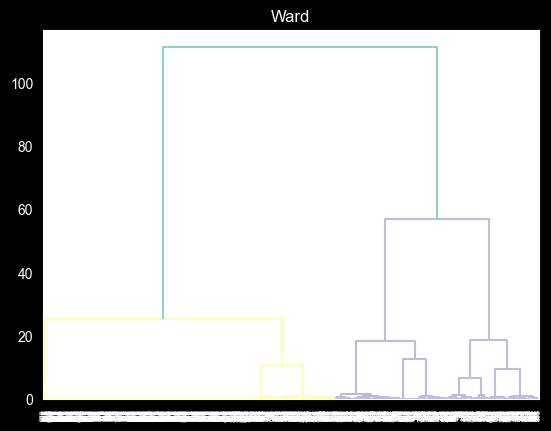

In [132]:
dendrogram(linkage(scaled_data,method='ward',metric='euclidean'))
plt.title('Ward')
plt.show()

In [ ]:
dendrogram(linkage(scaled_data,method='ward',metric='euclidean'))
plt.title('Ward')
plt.show()

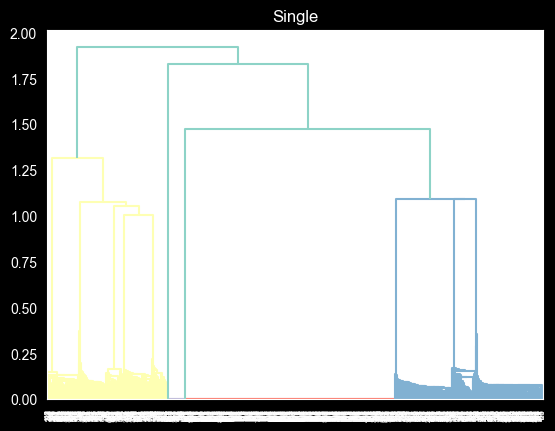

In [127]:
dendrogram(linkage(scaled_data,method='single',metric='euclidean'))
plt.title('Single')
plt.show()

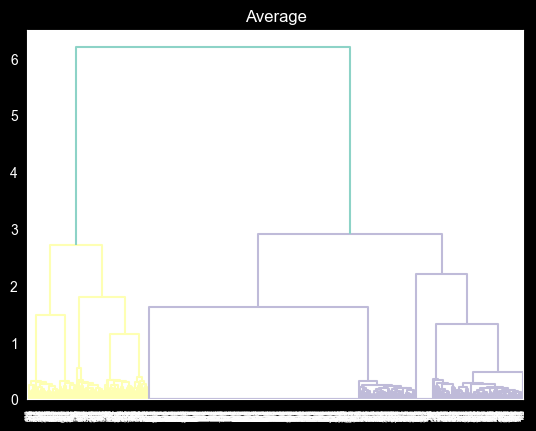

In [133]:
dendrogram(linkage(scaled_data,method='average',metric='euclidean'))
plt.title('Average')
plt.show()

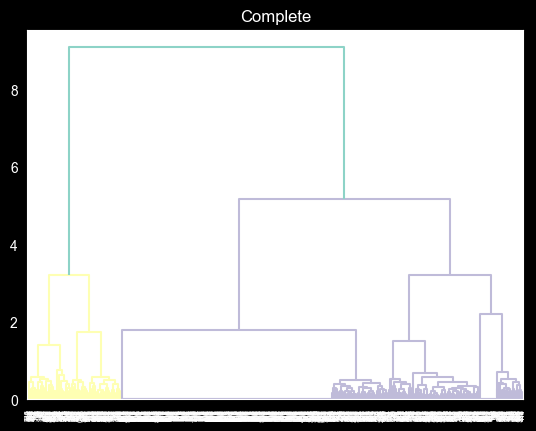

In [134]:
dendrogram(linkage(scaled_data,method='complete',metric='euclidean'))
plt.title('Complete')
plt.show()

# **ELBOW**

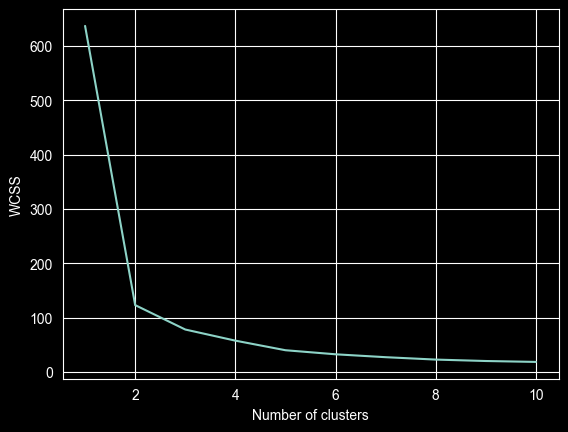

In [103]:
wcss=[]

for i in range(1,11):
    kmeans = cluster.KMeans(n_clusters=i,init='k-means++',n_init=1000,max_iter=100,random_state=0).fit(scaled_data)
    wcss.append(kmeans.inertia_)

plt.plot(range(1,11),wcss)
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')
plt.show()

In [ ]:
wc=[]

for i in range(1,11):
    km=cluster.KMeans(n_clusters=i,n_init=1000,max_iter=100,random_state=41,init='k-means++').fit(scaled_data)
    wc.append(km.inertia_)

plt.plot(range(1,11),wc)
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')
plt.show()
wc


In [ ]:
wc = []

for i in range(1,11)
    km=cluster.KMeans(n_clusters=i,n_init=1000,max_iter=100,random_state=41,init='k-means++').fit(scaled_data)
    wc.append(km.inertia_)

plt.plot(range(1,11),wc)
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')
plt.show()

In [ ]:
dendrogram(linkage(scaled_data,method='ward',metric='euclidean'))
plt.title('Ward')
plt.show()
dendrogram(linkage(scaled_data,method='single',metric='euclidean'))
plt.title('Ward')
plt.show()
dendrogram(linkage(scaled_data,method='average',metric='euclidean'))
plt.title('Ward')
plt.show()
dendrogram(linkage(scaled_data,method='complete',metric='euclidean'))
plt.title('Ward')
plt.show()

In [ ]:
km=cluster.KMeans().fit(scaled_data)

# Kmeans


In [102]:
kmeans=cluster.KMeans(n_clusters=2,n_init=100,max_iter=100,random_state=0)
kmeans.fit(scaled_data)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",2
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",100
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",100
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary `.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'


In [ ]:
km = cluster.KMeans(n_clusters=2,n_init=100,max_iter=100,random_state=0)
km.fit(scaled_data)

In [120]:
scaled_data.drop(columns=['released_year'],inplace=True)

In [121]:
scaled_data['cluster']=kmeans.labels_

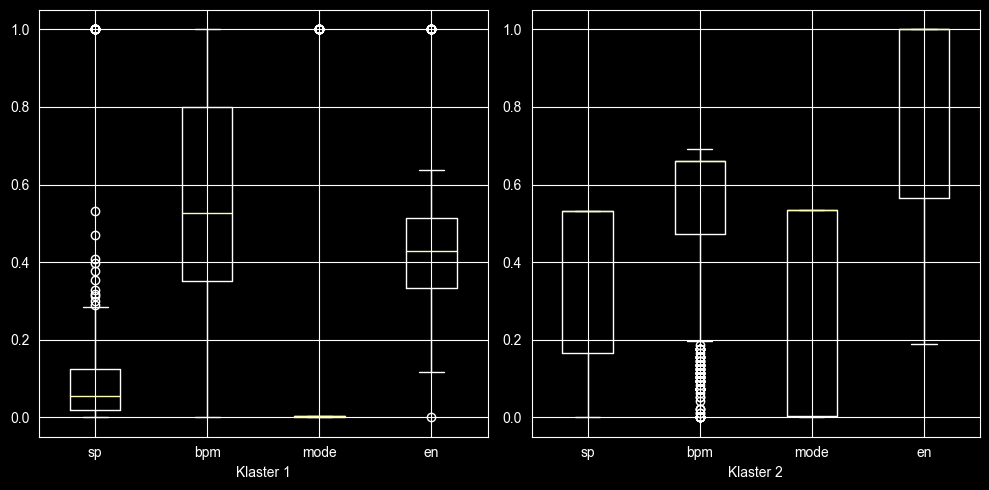

In [163]:
fig, ax = plt.subplots(1,2, figsize=(12,5))

ax[0].boxplot(scaled_data[scaled_data['cluster']==0].drop(columns='cluster'),labels=['sp','ap','bpm','mo','en'])
ax[0].set_xlabel('Klaster 1')

ax[1].boxplot(scaled_data[scaled_data['cluster']==1].drop(columns='cluster'),labels=['sp','ap','bpm','mo','en'])
ax[1].set_xlabel('Klaster 2')

plt.tight_layout()
plt.show()

# Hijerarhijska

In [135]:
h_k = cluster.AgglomerativeClustering(n_clusters=2,linkage='ward',metric='euclidean').fit(scaled_data)

In [ ]:
h=cluster.AgglomerativeClustering(n_clusters=2,linkage='single',metric='euclidean').fit(scaled_data)

In [ ]:
scaled_data['cluster']=h.labels_

In [147]:
scaled_data['cluster']=h_k.labels_

In [156]:

scaled_data.drop(columns=['in_apple_playlists'],inplace=True)

In [160]:

scaled_data.drop(columns=['klaster'],inplace=True)

In [161]:
scaled_data

,in_spotify_charts,bpm,mode,energy,cluster
0,0.532847,0.432990,0.003636,0.536232,0
1,0.171533,0.092784,0.003636,0.471014,1
2,0.408759,0.567010,0.003636,0.318841,0
3,0.007299,0.896907,0.003636,0.456522,0
4,0.178832,0.628866,0.000000,0.514493,0
...,...,...,...,...,...
947,0.532847,0.659794,0.534545,1.000000,1
948,0.532847,0.659794,0.534545,1.000000,1
949,0.532847,0.659794,0.534545,1.000000,1
950,0.532847,0.659794,0.534545,1.000000,1


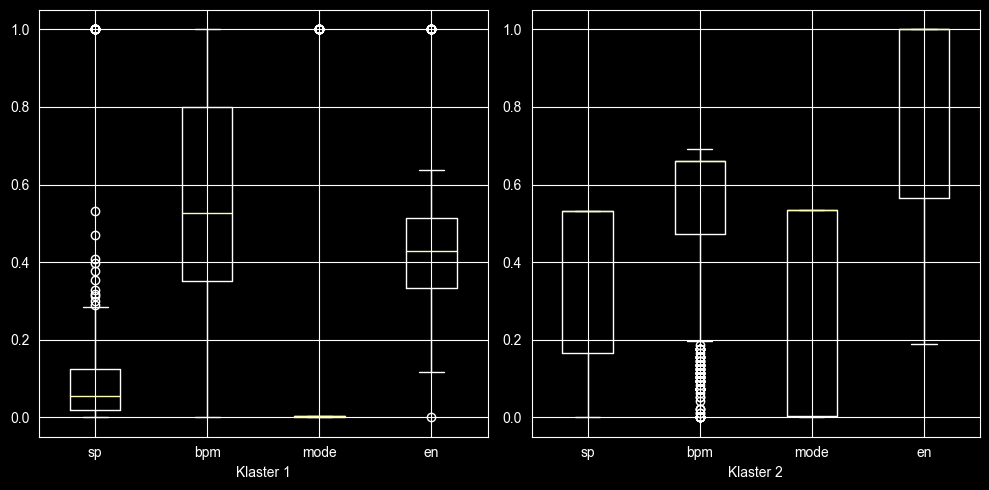

In [162]:
# Iscrtamo i uporedne boxplot-ove za ova dva klastera da bi ih uporedili u smislu sadržaja
fig, ax = plt.subplots(1,2,figsize=(10,5))

# U novijoj verziji matplotlib-a se umesto labels koristi tick_labels
ax[0].boxplot(scaled_data[scaled_data["cluster"]==0].drop(columns = ["cluster"]), labels=("sp", "bpm", "mode", "en"))
ax[0].set_xlabel("Klaster 1")

# U novijoj verziji matplotlib-a se umesto labels koristi tick_labels
ax[1].boxplot(scaled_data[scaled_data["cluster"]==1].drop(columns = ["cluster"]), labels=("sp", "bpm", "mode", "en"))
ax[1].set_xlabel("Klaster 2")

plt.tight_layout()
plt.show()

In [ ]:
fig,ax = plt.sublots(2,2,figsize=(10,8))
ax[0,0].boxplot(scaled_data[scaled_data["cluster"]==0].drop(columns=['cluster']),labels=('sp','bpm','mode','en'))
ax[0,0].set_xlabel("Klaster 1")
ax[0,1].boxplot(scaled_data[scaled_data["cluster"]==1].drop(columns=['cluster']),labels=('sp','bpm','mode','en'))
ax[0,1].set_xlabel("Klaster 2")
ax[1,0].boxplot(scaled_data[scaled_data["cluster"]==2].drop(columns=["cluster"]),labels=('sp','bpm','mode','en'))
ax[1,0].set_xlabel("Klaster 3")
ax[1,0].boxplot(scaled_data[scaled_data["cluster"]==3].drop(columns=["cluster"]),labels=('sp','bpm','mode','en'))
ax[1,0].set_xlabel("Klaster 4")


plt.tight_layout()
plt.show()

In [ ]:
ohe = OneHotEncoder(sparse_output=False,drop='first')
v = ['asd','fgh']

array = ohe.fit_transform(scaled_data[v])
col = ohe.get_feature_names_out(v)

data_ohe = pd.DataFrame(array,columns=col,index=scaled_data.index)
scaled_data = scaled_data.drop(columns=[v]).join(data_ohe)